# 🚦 Step 1 — Download GTSRB Traffic Sign Dataset

This notebook uses the **same `torchvision.datasets.GTSRB` approach as your Practical 5 notebook**, but handles download and visual inspection separately from training.

**Run once:** put `dataset_setup.ipynb`, `train_model.ipynb`, and `requirements.txt` together in the same location. In a terminal there, run:

```bash
python3 -m venv .venv
source .venv/bin/activate
python -m pip install -r requirements.txt
```

Select that Python environment as your notebook kernel. On Google Colab, upload the three files and run `!pip install -r requirements.txt` before these cells.

> Dataset download creates `data2/` automatically. This is downloaded **data**, not a fourth project source file. No manual Kaggle download is necessary.

## 1. Import the libraries

In [1]:
from pathlib import Path
from collections import Counter
import random
import matplotlib.pyplot as plt
from torchvision import datasets

SEED = 42
random.seed(SEED)
DATA_DIR = Path("./data2")  # Same location as in your Practical 5 notebook
NUM_CLASSES = 43


## 2. Download the official GTSRB training and testing datasets

In [2]:
print("Checking/downloading training images...")
train_dataset = datasets.GTSRB(
    root=str(DATA_DIR), split="train", download=True
)
print("Checking/downloading testing images and labels...")
test_dataset = datasets.GTSRB(
    root=str(DATA_DIR), split="test", download=True
)

print("\nDataset is ready!")
print("Training images:", len(train_dataset))
print("Testing images: ", len(test_dataset))
print("Classes:        ", NUM_CLASSES)
print("Saved under:   ", DATA_DIR.resolve())


Checking/downloading training images...


100%|██████████| 187M/187M [01:29<00:00, 2.08MB/s] 


Checking/downloading testing images and labels...


100%|██████████| 89.0M/89.0M [00:27<00:00, 3.25MB/s]
100%|██████████| 99.6k/99.6k [00:00<00:00, 208kB/s]


Dataset is ready!
Training images: 26640
Testing images:  12630
Classes:         43
Saved under:    /Users/neev/Downloads/DL/data2


## 3. Check labels, image sizes and class distribution

Sample image dimensions: (29, 30)
Sample image class ID:   0
Smallest class count:    150
Largest class count:     1500


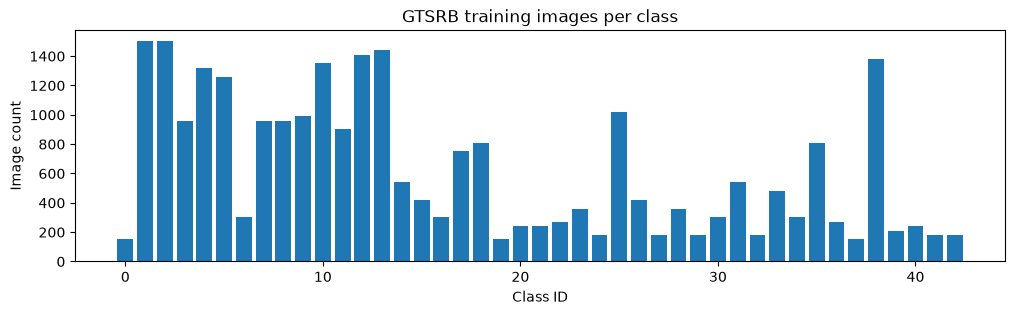

In [3]:
train_counts = Counter(int(label) for _, label in train_dataset._samples)
test_counts = Counter(int(label) for _, label in test_dataset._samples)
assert len(train_counts) == 43, f"Expected 43 training classes, found {len(train_counts)}"
assert len(test_counts) == 43, f"Expected 43 test classes, found {len(test_counts)}"

example_image, example_label = train_dataset[0]
print("Sample image dimensions:", example_image.size)
print("Sample image class ID:  ", example_label)
print("Smallest class count:   ", min(train_counts.values()))
print("Largest class count:    ", max(train_counts.values()))

fig, ax = plt.subplots(figsize=(12, 3))
ax.bar(sorted(train_counts), [train_counts[i] for i in sorted(train_counts)])
ax.set(title="GTSRB training images per class", xlabel="Class ID", ylabel="Image count")
plt.show()


## 4. View sample images

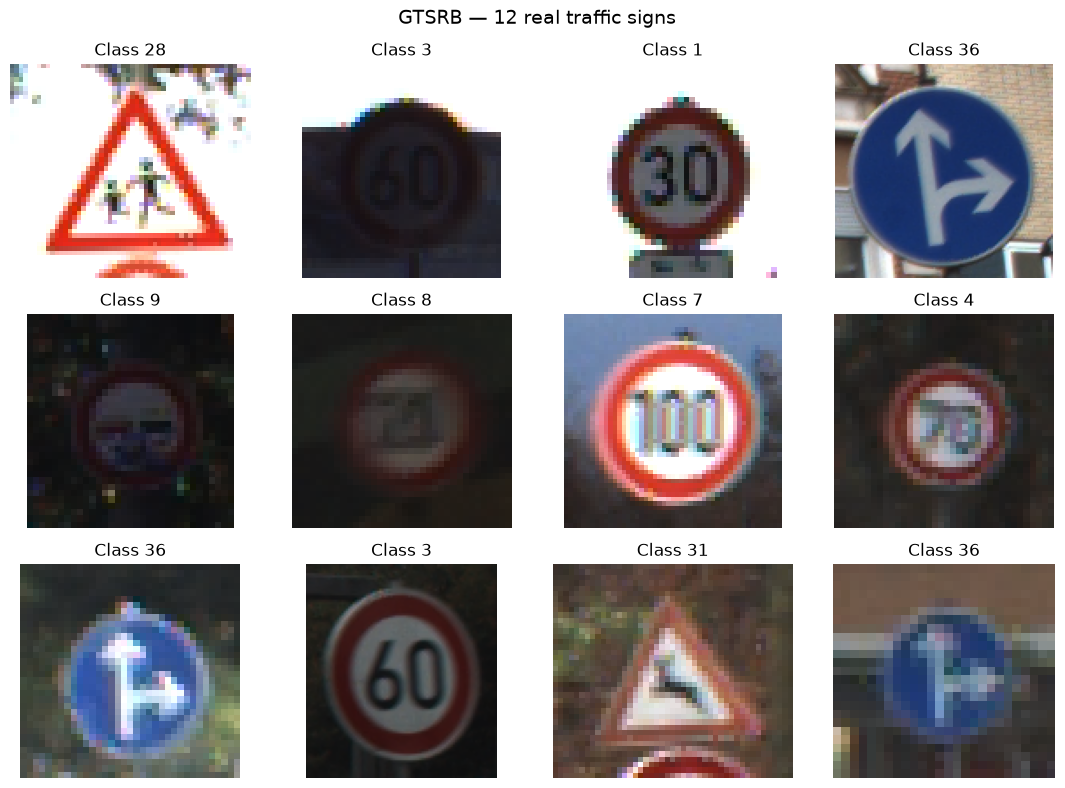

In [4]:
indices = random.sample(range(len(train_dataset)), 12)
fig, axes = plt.subplots(3, 4, figsize=(11, 8))
for ax, idx in zip(axes.flat, indices):
    image, label = train_dataset[idx]
    ax.imshow(image)
    ax.set_title(f"Class {label}")
    ax.axis("off")
fig.suptitle("GTSRB — 12 real traffic signs", fontsize=14)
plt.tight_layout()
plt.show()


## ✅ Next step

Open **`train_model.ipynb`** in the **same working directory** and run its cells in order.

- GTSRB train and test archives are stored automatically inside `data2/`.
- No need to download the dataset a second time.
- The training notebook creates a separate validation split **only from training data**, keeping the official test set untouched until the end.
- GTSRB is for **cropped traffic-sign classification**. Detecting signs in an entire road video will require a separate sign detector later.